In [1]:
##################
### Keagan Moo ###
### 2025/03/21 ###
### NucleiAge  ###
##################

# This script loads in the nuclei and sample level metadata to count the QC passing nuclei per sample per cell type
# and test them against age and potentially other metadata to see if nuceli abundance is associated with any sample 
# characteristics in our study.
suppressPackageStartupMessages(library(ggplot2))
suppressPackageStartupMessages(library(data.table))
suppressPackageStartupMessages(library(glue))
suppressPackageStartupMessages(library(dplyr))
suppressPackageStartupMessages(library(DESeq2))

In [2]:
infile <- "/nfs/turbo/umms-scjp/kgmoo/analysis/20240124_kgmoo_WolverineScripts/Files/ARIMAke/albanusScripts/KMOut2024_T2DnTSS/edger_per_cluster_fusion_only/Type_1.rds"
edger_results <- readRDS(infile)
tempType <- "Type_1"


In [3]:
barcode_md <- file.path(
  "/nfs/turbo/umms-scjp/arushiv/projects/muscle-sn/analyses_hg38/freeze/qc_fusion.bgstringent__k_21",
  paste0("cluster_info_qc.tsv")
) %>% 
  fread(data.table = F)

covariate_md <- file.path(
  "/nfs/turbo/umms-scjp/arushiv/projects/muscle-sn/analyses_hg38/freeze",
  paste0("sample_level_covariates_atac.tsv")
) %>% 
  fread(data.table = F)

covSNG <- data.frame(SNG = covariate_md$SNG.1ST, cluster = substr(covariate_md$coarse_cluster_name, 8, nchar(covariate_md$coarse_cluster_name)),
                     age = covariate_md$age, sex = covariate_md$sex, bmi = covariate_md$bmi, tss_enrichment_sampleCluster = covariate_md$tss_enrichment)

barcode_md$ID <- paste0(barcode_md$SNG.1ST, barcode_md$coarse_cluster_name)
covSNG$ID <- paste0(covSNG$SNG, covSNG$cluster)
covSNG <- covSNG[,!colnames(covSNG) %in% c("SNG", "cluster")]

barcode_md <- merge(barcode_md, covSNG, by = "ID")
barcode_md <- barcode_md[,!colnames(barcode_md) %in% c("ID")]

metadata.factors <- barcode_md %>% 
  group_by(sample) %>% 
  mutate(tss_enrich_median = median(tss_enrichment, na.rm = T),
         n_nuclei = n()) %>% 
  dplyr::select(sample, batch, cohort, age, sex, bmi, tss_enrich_median, n_nuclei) %>% 
  distinct() %>% 
  
  # fix wrong sex assignments
  mutate(sex = case_when(sample %in% c("SA02842--564", "SA02842--625") ~ "M", 
                         T ~ sex)) %>% 
  
  # Keep only FUSION samples
  dplyr::filter(cohort %in% "FUSION") %>% 
  
  # Format for model matrices
  mutate(sex = factor(sex, levels = c("M", "F"))) %>% 
  mutate(n_nuclei_l10 = log10(n_nuclei)) %>% 
  dplyr::filter(!is.na(age)) %>% 
  arrange(age) %>% 
  as.data.frame() %>% 
  
  # conform to Ucar script
  mutate(sampid = sample,
         batchdate = batch,
         nreps = 1)

In [4]:
# KM # Load in arushi's cell type specific TSS enrichment data so we can use that
TSSDat <- read.table("/nfs/turbo/umms-scjp/arushiv/projects/muscle-sn/analyses_hg38/freeze/cluster-sample-ataqv-stats.txt", header = TRUE)
nameFrame <- data.frame(t(data.frame(strsplit(TSSDat$name, "@"))))
rownames(nameFrame) <- NULL
colnames(nameFrame) <- c("Type","Cohort","sample")
TSSDat$Type <- nameFrame$Type
TSSDat$sample <- nameFrame$sample
TSSDat <- TSSDat[TSSDat$Type == glue("{tempType}"),]
TSSDat <- TSSDat %>% dplyr::select(c("sample", "tss_enrichment"))
metadata.factors <- merge(metadata.factors, TSSDat, by = "sample")

In [5]:
# KM # Load in T2D sample data to include in correction
SampleData <- read.table("/nfs/turbo/umms-scjp/arushiv/projects/muscle-sn/analyses_hg38/freeze/batch-sample-info-full.tsv", sep = "\t", header = TRUE)
SampleData <- SampleData[SampleData$sample %in% metadata.factors$sample,]
SampleData <- SampleData %>% dplyr::select(c("sample", "ogtt"))

metadata.factors <- merge(metadata.factors, SampleData, by = "sample")
rownames(metadata.factors) <- metadata.factors$sample

metadata.factors$batch <- as.factor(metadata.factors$batch)

In [6]:
# Fix missing samples
metadata.factors <- metadata.factors %>% 
  dplyr::filter(sample %in% colnames(edger_results$adj))


varClay <- as.data.frame(t(edger_results$adj))
varClay$age <- metadata.factors$age
test46 <- varClay[varClay$age == 46,]

ROWVARS <- function(x, ...) {
  rowSums((x - rowMeans(x, ...))^2, ...)/(dim(x)[2] - 1)
}

groupedClay <- varClay %>% group_split(age)
ages <- unique(varClay$age)
vars <- c()
means <- c()
for (i in 1:length(groupedClay)) {
  temp <- t(groupedClay[i][[1]])
  if (ncol(temp) < 2) {
    vars <- c(vars, -1)
  } else {
    rowVariance <- ROWVARS(temp)
    ageVariance <- mean(rowVariance)
    vars <- c(vars, ageVariance)
  }
  rowAvg <- rowMeans(temp)
  ageAvg <- mean(rowAvg)
  means <- c(means, ageAvg)
}

In [7]:
####################### AGE NUCLEI #####################################

barcode_md <- file.path(
  "/nfs/turbo/umms-scjp/arushiv/projects/muscle-sn/analyses_hg38/freeze/qc_fusion.bgstringent__k_21",
  paste0("cluster_info_qc.tsv")
) %>% 
  fread(data.table = F)
barcode_md <- barcode_md[barcode_md$sample != "multiome--3172",]
theFactor <- metadata.factors[,c("sample", "age")]
barcode_md <- merge(barcode_md, theFactor, by = "sample")

# Just atac nuclei, just rna nuclei, combined
barcode_md <- barcode_md#[barcode_md$modality == "atac",]
groupedClay <- barcode_md %>% arrange(age,sample) %>% group_split(sample)
countAge <- data.frame(coarse_cluster_name = sort(unique(barcode_md$coarse_cluster_name)))
propAge <- data.frame(coarse_cluster_name = sort(unique(barcode_md$coarse_cluster_name)))
ages <- c()
for (i in 1:length(groupedClay)) {
  #print(i)
  temp <- (groupedClay[i][[1]])
  #print(temp$age)
  counts <- temp %>% group_by(coarse_cluster_name) %>% dplyr::count()
  #print(counts)
  countAge <- merge(countAge, counts, by=1, all = TRUE)
  counts$n <- counts$n / sum(counts$n)
  propAge <- merge(propAge, counts, by=1, all = TRUE)
  ages <- c(ages,temp$age[1]) 
}
countAge[is.na(countAge)] <- 0
propAge[is.na(propAge)] <- 0
colnames(countAge) <- c("Type", ages)
colnames(propAge) <- colnames(countAge)

#propAge <- propAge[ , order(names(propAge))]
#colnames(propAge) <- gsub("\\b([0-9]{2})[^,]+", "\\1", colnames(propAge))
meltDFProp <- melt(propAge)
meltDF <- melt(countAge)

Warning message in merge.data.frame(countAge, counts, by = 1, all = TRUE):
“column names ‘n.x’, ‘n.y’ are duplicated in the result”
Warning message in merge.data.frame(propAge, counts, by = 1, all = TRUE):
“column names ‘n.x’, ‘n.y’ are duplicated in the result”
Warning message in merge.data.frame(countAge, counts, by = 1, all = TRUE):
“column names ‘n.x’, ‘n.y’ are duplicated in the result”
Warning message in merge.data.frame(propAge, counts, by = 1, all = TRUE):
“column names ‘n.x’, ‘n.y’ are duplicated in the result”
Warning message in merge.data.frame(countAge, counts, by = 1, all = TRUE):
“column names ‘n.x’, ‘n.y’, ‘n.x’, ‘n.y’ are duplicated in the result”
Warning message in merge.data.frame(propAge, counts, by = 1, all = TRUE):
“column names ‘n.x’, ‘n.y’, ‘n.x’, ‘n.y’ are duplicated in the result”
Warning message in merge.data.frame(countAge, counts, by = 1, all = TRUE):
“column names ‘n.x’, ‘n.y’, ‘n.x’, ‘n.y’ are duplicated in the result”
Warning message in merge.data.frame(p

In [8]:
####################### Now with DESeq2 #####################################
sample_md <- covariate_md %>% dplyr::select(c("SNG.1ST","batch","sex","bmi","age")) %>% unique() %>% arrange(SNG.1ST)
# sample_md <- sample_md[sample_md$age > 40,]
sample_md$age <- as.numeric(sample_md$age)
sample_md$bmi <- as.numeric(sample_md$bmi)
sample_md$SNG.1ST <- as.factor(sample_md$SNG.1ST)
sample_md$batch <- as.factor(sample_md$batch)
sample_md$sex <- as.factor(sample_md$sex)
sample_md$libsize <- as.numeric(colSums(countAge[-1]))
justOGTT <- metadata.factors %>% dplyr::select(sample, ogtt)
sample_md <- cbind(sample_md, justOGTT)


countAgeDESeq <- countAge
colnames(countAgeDESeq) <- NULL

propAgeDESeq <- propAge
colnames(propAgeDESeq) <- NULL

#sample_md$size <- as.numeric(colSums(countAge[,-1])) DESeq2 already handles n_nuclei
head(propAgeDESeq)
head(sample_md)

sample_mdF <- sample_md[sample_md$sex == "F",]
sample_mdM <- sample_md[sample_md$sex == "M",]

FVector <- c(TRUE, (sample_md$sex == "F"))
MVector <- c(TRUE, (sample_md$sex == "M"))
countAgeDESeqF <- countAgeDESeq[,FVector]
countAgeDESeqM <- countAgeDESeq[,MVector]

propAgeDESeqF <- propAgeDESeq[,FVector]
propAgeDESeqM <- propAgeDESeq[,MVector]

#head(propAgeDESeqF[-1])
#head(propAgeDESeqM[-1])

head(countAgeDESeqF)
head(countAgeDESeqM)
head(propAgeDESeqF)
head(propAgeDESeqM)

1,Adipocyte,0.008660214,0.021004566,0.004939210,0.017621145,0.006951872,0.005610973,0.006861848,0.015340364,0.11666667,⋯,0.013642565,0.014517506,0.014696059,0.01615695,0.008480565,0.016617211,0.01704800,0.007815892,0.01098039,0.004329004
2,Endothelial,0.084564442,0.137899543,0.059650456,0.109331197,0.106951872,0.110349127,0.066331199,0.118887824,0.23333333,⋯,0.091405184,0.077711358,0.112224449,0.10098096,0.060777385,0.100890208,0.09645581,0.095093356,0.10862745,0.108225108
3,Macrophage,0.006622517,0.021917808,0.006079027,0.005606728,0.010160428,0.008728180,0.001829826,0.006232023,0.06666667,⋯,0.004774898,0.005123826,0.004008016,0.01096365,0.011307420,0.004747774,0.01345895,0.013026487,0.01490196,0.006493506
4,Mesenchymal_Stem_Cell,0.048395313,0.116894977,0.039513678,0.042851422,0.044919786,0.052992519,0.034309241,0.046979866,0.03333333,⋯,0.047066849,0.035012810,0.044088176,0.05597230,0.038162544,0.039169139,0.04351727,0.043855840,0.06823529,0.052669553
5,Muscle_Fiber_Mixed,0.001018849,0.005479452,0.011018237,0.024429315,0.017647059,0.012468828,0.008234218,0.011505273,0.00000000,⋯,0.008185539,0.031596926,0.031396126,0.02077323,0.010600707,0.013649852,0.01884253,0.017368650,0.01137255,0.010822511
6,Neuromuscular_junction,0.010697911,0.010958904,0.044072948,0.020424509,0.006951872,0.008104738,0.006861848,0.011984660,0.01666667,⋯,0.008867667,0.024765158,0.031396126,0.01731102,0.028975265,0.008308605,0.01345895,0.020408163,0.01294118,0.025974026


,SNG.1ST,batch,sex,bmi,age,libsize,sample,ogtt
,<fct>,<fct>,<fct>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
12001--510,12001,510-NM,M,30.37742,66,1963,12001--510,IGT
12002--551,12002,551-NM,M,25.10174,61,1095,12002--551,NGT
12003--530,12003,530-NM,M,25.51226,58,2632,12003--530,NGT
12004--530,12004,530-NM,M,23.03005,64,2497,12004--530,NGT
12006--530,12006,530-NM,F,22.79218,56,1870,12006--530,NGT
12007--647,12007,647-NM,F,21.35780,64,1604,12007--647,IGT


1,Adipocyte,13,9,14,35,5,17,15,12,10,⋯,4,34,16,29,31,20,17,12,28,38
2,Endothelial,200,177,28,192,108,106,141,105,159,⋯,45,233,196,219,246,134,91,86,170,215
3,Macrophage,19,14,8,18,7,26,8,6,9,⋯,2,9,23,34,19,7,6,16,8,30
4,Mesenchymal_Stem_Cell,84,85,4,99,51,96,50,47,51,⋯,20,60,71,98,121,69,41,54,66,97
5,Muscle_Fiber_Mixed,33,20,0,28,12,15,7,24,48,⋯,1,29,59,5,33,12,37,15,23,42
6,Neuromuscular_junction,13,13,2,55,9,45,9,6,33,⋯,10,25,20,60,57,13,29,41,14,30


1,Adipocyte,17,23,13,44,15,32,21,14,6,⋯,10,8,4,23,14,22,28,18,28,6
2,Endothelial,166,151,157,273,145,248,169,135,79,⋯,110,231,98,202,147,168,175,219,277,150
3,Macrophage,13,24,16,14,4,13,13,12,2,⋯,6,15,15,9,26,6,19,30,38,9
4,Mesenchymal_Stem_Cell,95,128,104,107,75,98,81,74,28,⋯,63,86,43,91,76,66,97,101,174,73
5,Muscle_Fiber_Mixed,2,6,29,61,18,24,50,6,0,⋯,20,7,13,63,40,47,36,40,29,15
6,Neuromuscular_junction,21,12,116,51,15,25,17,9,4,⋯,43,17,42,51,38,47,30,47,33,36


1,Adipocyte,0.006951872,0.005610973,0.11666667,0.017173700,0.003843198,0.01326053,0.010409438,0.009892828,0.005037783,⋯,0.007299270,0.016433059,0.007615421,0.012446352,0.010480054,0.013642565,0.014517506,0.008480565,0.016617211,0.01704800
2,Endothelial,0.106951872,0.110349127,0.23333333,0.094210010,0.083013067,0.08268331,0.097848716,0.086562242,0.080100756,⋯,0.082116788,0.112614790,0.093288910,0.093991416,0.083164300,0.091405184,0.077711358,0.060777385,0.100890208,0.09645581
3,Macrophage,0.010160428,0.008728180,0.06666667,0.008832188,0.005380477,0.02028081,0.005551700,0.004946414,0.004534005,⋯,0.003649635,0.004349928,0.010947168,0.014592275,0.006423259,0.004774898,0.005123826,0.011307420,0.004747774,0.01345895
4,Mesenchymal_Stem_Cell,0.044919786,0.052992519,0.03333333,0.048577036,0.039200615,0.07488300,0.034698126,0.038746908,0.025692695,⋯,0.036496350,0.028999517,0.033793432,0.042060086,0.040906018,0.047066849,0.035012810,0.038162544,0.039169139,0.04351727
5,Muscle_Fiber_Mixed,0.017647059,0.012468828,0.00000000,0.013738960,0.009223674,0.01170047,0.004857738,0.019785655,0.024181360,⋯,0.001824818,0.014016433,0.028081866,0.002145923,0.011156187,0.008185539,0.031596926,0.010600707,0.013649852,0.01884253
6,Neuromuscular_junction,0.006951872,0.008104738,0.01666667,0.026987242,0.006917756,0.03510140,0.006245663,0.004946414,0.016624685,⋯,0.018248175,0.012083132,0.009519277,0.025751073,0.019269777,0.008867667,0.024765158,0.028975265,0.008308605,0.01345895


1,Adipocyte,0.008660214,0.021004566,0.004939210,0.017621145,0.006861848,0.015340364,0.009571559,0.014155713,0.013100437,⋯,0.007716049,0.005532503,0.004357298,0.010295434,0.01030169,0.014696059,0.01615695,0.007815892,0.01098039,0.004329004
2,Endothelial,0.084564442,0.137899543,0.059650456,0.109331197,0.066331199,0.118887824,0.077028259,0.136501517,0.172489083,⋯,0.084876543,0.159751037,0.106753813,0.090420770,0.10816777,0.112224449,0.10098096,0.095093356,0.10862745,0.108225108
3,Macrophage,0.006622517,0.021917808,0.006079027,0.005606728,0.001829826,0.006232023,0.005925251,0.012133468,0.004366812,⋯,0.004629630,0.010373444,0.016339869,0.004028648,0.01913171,0.004008016,0.01096365,0.013026487,0.01490196,0.006493506
4,Mesenchymal_Stem_Cell,0.048395313,0.116894977,0.039513678,0.042851422,0.034309241,0.046979866,0.036918870,0.074823054,0.061135371,⋯,0.048611111,0.059474412,0.046840959,0.040734109,0.05592347,0.044088176,0.05597230,0.043855840,0.06823529,0.052669553
5,Muscle_Fiber_Mixed,0.001018849,0.005479452,0.011018237,0.024429315,0.008234218,0.011505273,0.022789426,0.006066734,0.000000000,⋯,0.015432099,0.004840941,0.014161220,0.028200537,0.02943341,0.031396126,0.02077323,0.017368650,0.01137255,0.010822511
6,Neuromuscular_junction,0.010697911,0.010958904,0.044072948,0.020424509,0.006861848,0.011984660,0.007748405,0.009100101,0.008733624,⋯,0.033179012,0.011756570,0.045751634,0.022829006,0.02796174,0.031396126,0.01731102,0.020408163,0.01294118,0.025974026


In [29]:
jitterFrame <- data.frame(t(countAgeDESeq))
colnames(jitterFrame) <- jitterFrame[1,]
jitterFrame <- jitterFrame[-1,]
jitterFrame <- cbind(sample_md, jitterFrame)
head(jitterFrame)
jitterFrame[jitterFrame$SNG.1ST == "12001",]

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240124_kgmoo_WolverineScripts/KMScripts_Update/Plots/Adipocytes_NucleiCounts_Sex.pdf"), width=6, height=6)
myplot <- ggplot(jitterFrame, aes(x = sex, y = as.numeric(Adipocyte))) + 
  geom_jitter() + 
  theme_bw() + scale_y_continuous(limits = c(0, 200), breaks = seq(0, 200, 50)) + 
  ylab("Nuclei in Sample") + xlab("Sex") + ggtitle(glue("Nuclei Count in Adipocytes")) 
print(myplot)
dev.off()

,SNG.1ST,batch,sex,bmi,age,libsize,sample,ogtt,Adipocyte,Endothelial,⋯,Mesenchymal_Stem_Cell,Muscle_Fiber_Mixed,Neuromuscular_junction,Neuronal,Satellite_Cell,Smooth_Muscle,T_cell,Type_1,Type_2a,Type_2x
,<fct>,<fct>,<fct>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
12001--510,12001,510-NM,M,30.37742,66,1963,12001--510,IGT,17,166,⋯,95,2,21,53,52,46,82,639,339,438
12002--551,12002,551-NM,M,25.10174,61,1095,12002--551,NGT,23,151,⋯,128,6,12,25,13,52,44,180,116,321
12003--530,12003,530-NM,M,25.51226,58,2632,12003--530,NGT,13,157,⋯,104,29,116,48,32,66,71,852,510,618
12004--530,12004,530-NM,M,23.03005,64,2497,12004--530,NGT,44,273,⋯,107,61,51,124,50,94,155,418,477,629
12006--530,12006,530-NM,F,22.79218,56,1870,12006--530,NGT,13,200,⋯,84,33,13,65,40,79,71,962,216,75
12007--647,12007,647-NM,F,21.35780,64,1604,12007--647,IGT,9,177,⋯,85,20,13,35,24,82,69,663,208,205


,SNG.1ST,batch,sex,bmi,age,libsize,sample,ogtt,Adipocyte,Endothelial,⋯,Mesenchymal_Stem_Cell,Muscle_Fiber_Mixed,Neuromuscular_junction,Neuronal,Satellite_Cell,Smooth_Muscle,T_cell,Type_1,Type_2a,Type_2x
,<fct>,<fct>,<fct>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
12001--510,12001,510-NM,M,30.37742,66,1963,12001--510,IGT,17,166,⋯,95,2,21,53,52,46,82,639,339,438


pdf 
  2

In [ ]:
dds <- DESeqDataSetFromMatrix(countData = as.matrix(countAgeDESeq[,-1]),
                              colData = sample_md,
                              design= ~ batch + sex + bmi + ogtt + age)
dds <- DESeq(dds)
resultsNames(dds)
res <- results(dds, name="age")
resex <- results(dds, name="sex_M_vs_F")

ddsF <- DESeqDataSetFromMatrix(countData = as.matrix(countAgeDESeqF[,-1]),
                              colData = sample_mdF,
                              design= ~ batch + bmi + ogtt + age)
ddsF <- DESeq(ddsF)
resultsNames(ddsF)
resF <- results(ddsF, name="age")

ddsM <- DESeqDataSetFromMatrix(countData = as.matrix(countAgeDESeqM[,-1]),
                              colData = sample_mdM,
                              design= ~ batch + bmi + ogtt + age)
ddsM <- DESeq(ddsM)
resultsNames(ddsM)
resM <- results(ddsM, name="age")

converting counts to integer mode

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”
  the design formula contains one or more numeric variables with integer values,
  specifying a model with increasing fold change for higher values.
  did you mean for this to be a factor? if so, first convert
  this variable to a factor using the factor() function

  the design formula contains one or more numeric variables that have mean or
  standard deviation larger than 5 (an arbitrary threshold to trigger this message).
  Including numeric variables with large mean can induce collinearity with the intercept.
  Users should center and scale numeric variables in the design to improve GLM convergence.

  Note: levels of factors in the design contain characters other than
  letters, numbers, '_' and '.'. It is recommended (but not required) to use
  only letters, numbers, and delimiters '_' or '.', as these are s

[1] "Intercept"              "batch_510.NM_vs_499.NM" "batch_530.NM_vs_499.NM"
 [4] "batch_551.NM_vs_499.NM" "batch_564.NM_vs_499.NM" "batch_567.NM_vs_499.NM"
 [7] "batch_625.NM_vs_499.NM" "batch_647.NM_vs_499.NM" "batch_678.NM_vs_499.NM"
[10] "batch_692.NM_vs_499.NM" "sex_M_vs_F"             "bmi"                   
[13] "ogtt_IGT_vs_IFG"        "ogtt_NGT_vs_IFG"        "ogtt_T2D_vs_IFG"       
[16] "age"

converting counts to integer mode

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”
  the design formula contains one or more numeric variables with integer values,
  specifying a model with increasing fold change for higher values.
  did you mean for this to be a factor? if so, first convert
  this variable to a factor using the factor() function

  the design formula contains one or more numeric variables that have mean or
  standard deviation larger than 5 (an arbitrary threshold to trigger this message).
  Including numeric variables with large mean can induce collinearity with the intercept.
  Users should center and scale numeric variables in the design to improve GLM convergence.

  Note: levels of factors in the design contain characters other than
  letters, numbers, '_' and '.'. It is recommended (but not required) to use
  only letters, numbers, and delimiters '_' or '.', as these are s

[1] "Intercept"              "batch_510.NM_vs_499.NM" "batch_530.NM_vs_499.NM"
 [4] "batch_551.NM_vs_499.NM" "batch_564.NM_vs_499.NM" "batch_567.NM_vs_499.NM"
 [7] "batch_625.NM_vs_499.NM" "batch_647.NM_vs_499.NM" "batch_678.NM_vs_499.NM"
[10] "batch_692.NM_vs_499.NM" "bmi"                    "ogtt_IGT_vs_IFG"       
[13] "ogtt_NGT_vs_IFG"        "ogtt_T2D_vs_IFG"        "age"

converting counts to integer mode

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”
  the design formula contains one or more numeric variables with integer values,
  specifying a model with increasing fold change for higher values.
  did you mean for this to be a factor? if so, first convert
  this variable to a factor using the factor() function

  the design formula contains one or more numeric variables that have mean or
  standard deviation larger than 5 (an arbitrary threshold to trigger this message).
  Including numeric variables with large mean can induce collinearity with the intercept.
  Users should center and scale numeric variables in the design to improve GLM convergence.

  Note: levels of factors in the design contain characters other than
  letters, numbers, '_' and '.'. It is recommended (but not required) to use
  only letters, numbers, and delimiters '_' or '.', as these are s

[1] "Intercept"              "batch_510.NM_vs_499.NM" "batch_530.NM_vs_499.NM"
 [4] "batch_551.NM_vs_499.NM" "batch_564.NM_vs_499.NM" "batch_567.NM_vs_499.NM"
 [7] "batch_625.NM_vs_499.NM" "batch_647.NM_vs_499.NM" "batch_678.NM_vs_499.NM"
[10] "batch_692.NM_vs_499.NM" "bmi"                    "ogtt_IGT_vs_IFG"       
[13] "ogtt_NGT_vs_IFG"        "ogtt_T2D_vs_IFG"        "age"

In [31]:
DEFrame <- data.frame(Types = countAge$Type, log2FC = res[[2]], log2FCSE = res[[3]], pval = res[[5]], padj = res[[6]])
DEFrame$log2FC_CU <- DEFrame$log2FC + DEFrame$log2FCSE*1.959964#1.64485#
DEFrame$log2FC_CL <- DEFrame$log2FC - DEFrame$log2FCSE*1.959964#1.64485#
DEFrame$Confidence <- DEFrame$padj < 0.05

DEFrame$Confidence <- factor(DEFrame$Confidence, levels = c("TRUE","FALSE"))
DEFrame$Types[4] <- "FAP"
DEFrame$Types <- gsub("_", " ", DEFrame$Types)

CellOrder <- rev(c("Type 1", "Type 2a","Type 2x", "Endothelial", "FAP", "Smooth Muscle",
               "T cell", "Neuronal", "Neuromuscular junction", "Muscle Fiber Mixed",
               "Satellite Cell", "Adipocyte", "Macrophage"))
ColorFrame <- data.frame(Types = CellOrder, Color =rev(c("#A2D7E8", "#207CBB", "#89D9C9", "#FF999D", "#52389E", 
                   "#FFBD6F", "#FA2D18", "#FDE854", "#B0DB8D", "#3CA646",
                   "#CBB9DC", "#919C9A", "#BD5523")))

DEFrame <- merge(DEFrame, ColorFrame, by = "Types")

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240124_kgmoo_WolverineScripts/KMScripts_Update/Plots/GLMChecks/DESeq2_ResultsFDR005_TotalCountLib.pdf"), width=8, height=6)
myplot <- ggplot(DEFrame, aes(log2FC, factor(Types, levels = CellOrder))) + 
  geom_point(aes(size = 3, color = Confidence)) + 
  geom_errorbar(aes(xmin = log2FC_CL, xmax = log2FC_CU, color = Confidence)) + geom_vline(xintercept = 0, linetype = "dashed") +
  theme_bw() + theme(text=element_text(size=24), legend.position="none") + scale_color_manual(values = c("#FF0000", "#000000")) +
  ylab("Nuclei Type") + xlab("Abundance log2 fold change") + ggtitle(glue("")) + xlim(-0.06,0.06)
print(myplot)
dev.off()

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240124_kgmoo_WolverineScripts/KMScripts_Update/Plots/GLMChecks/DESeq2_ResultsFDR005_TotalCountLib_Ledge.pdf"), width=2.5, height=5)
myplot <- ggplot(DEFrame, aes(log2FC, factor(Types, levels = CellOrder))) + 
  geom_point(aes(size = 3, color = Confidence)) + 
  geom_errorbar(aes(xmin = log2FC_CL, xmax = log2FC_CU, color = Confidence), lwd = 2.2) + geom_vline(xintercept = 0, linetype = "dashed") +
  theme_bw() + theme(text=element_text(size=24), axis.ticks.y=element_blank(), axis.text.y=element_blank()) + scale_color_manual(values = c( "#FF0000", "#000000")) +
  ylab("") + xlab("") + ggtitle(glue("")) + xlim(-0.06,0.06)
print(myplot)
dev.off()

pdf 
  2

pdf 
  2

In [29]:
DEFrame <- data.frame(Types = countAge$Type, log2FC = res[[2]], log2FCSE = res[[3]], pval = res[[5]])
DEFrame$log2FC_CU <- DEFrame$log2FC + DEFrame$log2FCSE*1.64485#1.959964
DEFrame$log2FC_CL <- DEFrame$log2FC - DEFrame$log2FCSE*1.64485#1.959964
DEFrame$Confidence <- (sign(DEFrame$log2FC_CU * DEFrame$log2FC_CL) > 0)

DEFrame$Types[4] <- "FAP"
DEFrame$Types <- gsub("_", " ", DEFrame$Types)

CellOrder <- rev(c("Type 1", "Type 2a","Type 2x", "Endothelial", "FAP", "Smooth Muscle",
               "T cell", "Neuronal", "Neuromuscular junction", "Muscle Fiber Mixed",
               "Satellite Cell", "Adipocyte", "Macrophage"))
ColorFrame <- data.frame(Types = CellOrder, Color =rev(c("#A2D7E8", "#207CBB", "#89D9C9", "#FF999D", "#52389E", 
                   "#FFBD6F", "#FA2D18", "#FDE854", "#B0DB8D", "#3CA646",
                   "#CBB9DC", "#919C9A", "#BD5523")))

DEFrame <- merge(DEFrame, ColorFrame, by = "Types")

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240124_kgmoo_WolverineScripts/KMScripts_Update/Plots/GLMChecks/DESeq2_ResultsFDR01_TotalCountLib.pdf"), width=6, height=6)
myplot <- ggplot(DEFrame, aes(log2FC, factor(Types, levels = CellOrder))) + 
  geom_point(aes(size = 3, color = Confidence)) + 
  geom_errorbar(aes(xmin = log2FC_CL, xmax = log2FC_CU, color = Confidence)) + geom_vline(xintercept = 0, linetype = "dashed") +
  theme_bw() + theme(text=element_text(size=14), legend.position="none") + scale_color_manual(values = c("#000000", "#FF0000")) +
  ylab("Nuclei Type") + xlab("Nuclei abundance log2 fold change") + ggtitle(glue("Nuclei Count Age Effects by DESeq2")) 
print(myplot)
dev.off()

pdf 
  2

In [45]:
DEFrameF <- data.frame(Types = countAgeDESeqF[,1], log2FC = resF[[2]], log2FCSE = resF[[3]], pval = resF[[5]])
DEFrameF$log2FC_CU <- DEFrameF$log2FC + DEFrameF$log2FCSE*1.64485#1.959964
DEFrameF$log2FC_CL <- DEFrameF$log2FC - DEFrameF$log2FCSE*1.64485#1.959964
DEFrameF$Confidence <- (sign(DEFrameF$log2FC_CU * DEFrameF$log2FC_CL) > 0)

DEFrameF$Types[4] <- "FAP"
DEFrameF$Types <- gsub("_", " ", DEFrameF$Types)

CellOrder <- rev(c("Type 1", "Type 2a","Type 2x", "Endothelial", "FAP", "Smooth Muscle",
               "T cell", "Neuronal", "Neuromuscular junction", "Muscle Fiber Mixed",
               "Satellite Cell", "Adipocyte", "Macrophage"))

DEFrameF <- merge(DEFrameF, ColorFrame, by = "Types")

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240124_kgmoo_WolverineScripts/KMScripts_Update/Plots/GLMChecks/DESeq2_ResultsFDR01_TotalCountLib_Fe.pdf"), width=6, height=6)
myplot <- ggplot(DEFrameF, aes(log2FC, factor(Types, levels = CellOrder))) + 
  geom_point(aes(size = 3, color = Confidence)) + 
  geom_errorbar(aes(xmin = log2FC_CL, xmax = log2FC_CU, color = Confidence)) + geom_vline(xintercept = 0, linetype = "dashed") +
  theme_bw() + theme(text=element_text(size=14), legend.position="none") + scale_color_manual(values = c("#000000", "#FF0000")) +
  ylab("Nuclei Type") + xlab("Nuclei abundance log2 fold change") + ggtitle(glue("Nuclei Count Age Effects by DESeq2")) 
print(myplot)
dev.off()

DEFrameM <- data.frame(Types = countAgeDESeqM[,1], log2FC = resM[[2]], log2FCSE = resM[[3]], pval = resM[[5]])
DEFrameM$log2FC_CU <- DEFrameM$log2FC + DEFrameM$log2FCSE*1.64485#1.959964
DEFrameM$log2FC_CL <- DEFrameM$log2FC - DEFrameM$log2FCSE*1.64485#1.959964
DEFrameM$Confidence <- (sign(DEFrameM$log2FC_CU * DEFrameM$log2FC_CL) > 0)

DEFrameM$Types[4] <- "FAP"
DEFrameM$Types <- gsub("_", " ", DEFrameM$Types)

DEFrameM <- merge(DEFrameM, ColorFrame, by = "Types")

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240124_kgmoo_WolverineScripts/KMScripts_Update/Plots/GLMChecks/DESeq2_ResultsFDR01_TotalCountLib_Ma.pdf"), width=6, height=6)
myplot <- ggplot(DEFrameM, aes(log2FC, factor(Types, levels = CellOrder))) + 
  geom_point(aes(size = 3, color = Confidence)) + 
  geom_errorbar(aes(xmin = log2FC_CL, xmax = log2FC_CU, color = Confidence)) + geom_vline(xintercept = 0, linetype = "dashed") +
  theme_bw() + theme(text=element_text(size=14), legend.position="none") + scale_color_manual(values = c("#000000", "#FF0000")) +
  ylab("Nuclei Type") + xlab("Nuclei abundance log2 fold change") + ggtitle(glue("Nuclei Count Age Effects by DESeq2")) 
print(myplot)
dev.off()

DEFrameF$Sex <- "Female"
DEFrameM$Sex <- "Male"
DEFrame <- rbind(DEFrameF, DEFrameM)

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240124_kgmoo_WolverineScripts/KMScripts_Update/Plots/GLMChecks/DESeq2_ResultsFDR01_TotalCountLib_MaFe.pdf"), width=6, height=6)
myplot <- ggplot(DEFrame, aes(log2FC, factor(Types, levels = CellOrder))) + 
  geom_point(aes(size = 3, color = Confidence)) + 
  geom_errorbar(aes(xmin = log2FC_CL, xmax = log2FC_CU, color = Sex)) + geom_vline(xintercept = 0, linetype = "dashed") +
  theme_bw() + theme(text=element_text(size=14), legend.position="none") + scale_color_manual(values = c("#000000", "#FF00FF", "#0000FF", "#FF0000")) +
  ylab("Nuclei Type") + xlab("Nuclei abundance log2 fold change") + ggtitle(glue("Nuclei Count Age Effects by DESeq2")) 
print(myplot)
dev.off()

pdf 
  2

pdf 
  2

pdf 
  2

In [33]:
F2xnuc <- countAgeDESeqF[13,]
F2x <- data.frame(age = sample_mdF$age, nuc = t(F2xnuc[-1]))
M2xnuc <- countAgeDESeqM[13,]
M2x <- data.frame(age = sample_mdM$age, nuc = t(M2xnuc[-1]))

Warning message in cor.test.default(F2x$age, F2x$X13, method = "spearman"):
“Cannot compute exact p-value with ties”



	Spearman's rank correlation rho

data:  F2x$age and F2x$X13
S = 314753, p-value = 0.3125
alternative hypothesis: true rho is not equal to 0
sample estimates:
        rho 
-0.09296777 


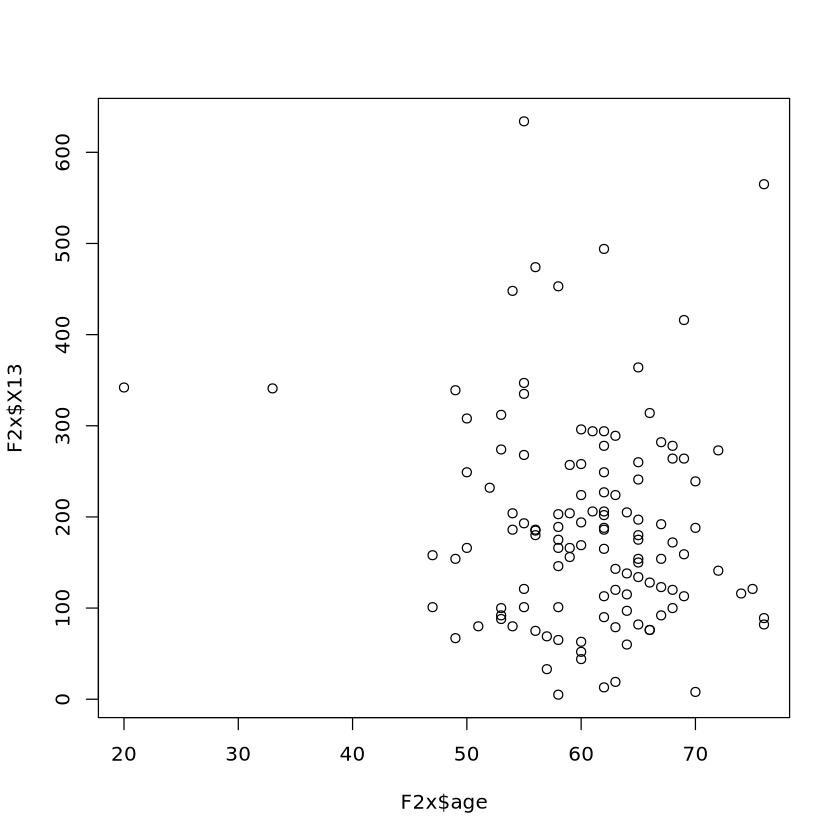

Warning message in cor.test.default(M2x$age, M2x$X13, method = "spearman"):
“Cannot compute exact p-value with ties”



	Spearman's rank correlation rho

data:  M2x$age and M2x$X13
S = 762222, p-value = 0.6394
alternative hypothesis: true rho is not equal to 0
sample estimates:
        rho 
-0.03685397 


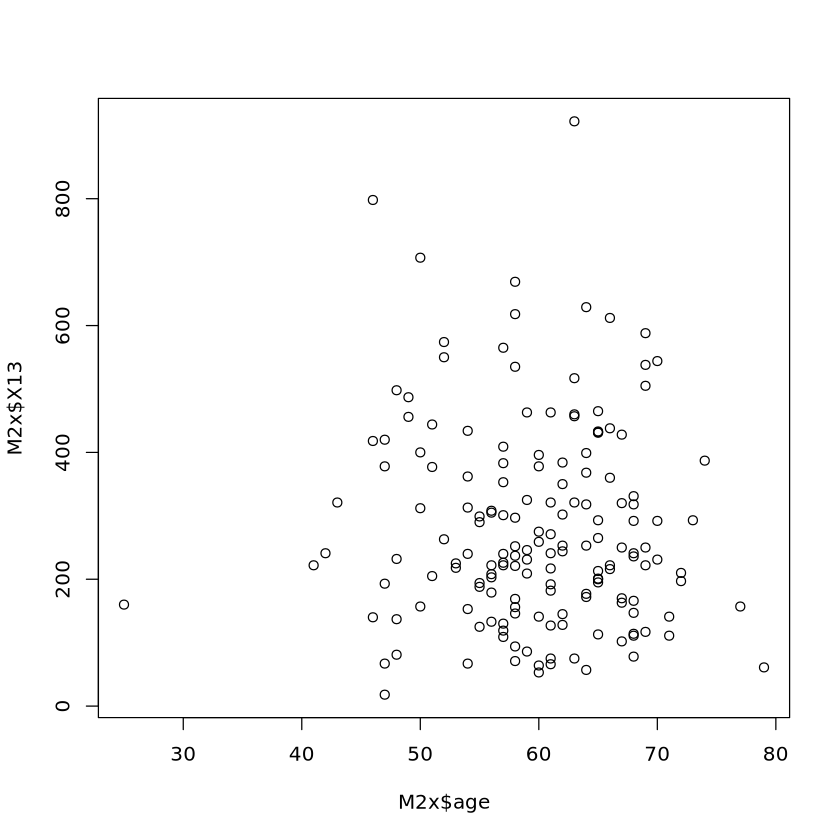

In [39]:
plot(F2x$age, F2x$X13)
cor.test(F2x$age, F2x$X13, method = "spearman")
plot(M2x$age, M2x$X13)
cor.test(M2x$age, M2x$X13, method = "spearman")